<a href="https://colab.research.google.com/github/Mangbunn/nets7052_fa26/blob/main/final_project_notebook_frfr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inference on Trees: Learning From, and About, Tree-Structured Networks
In this chapter we will:

1. Explain why **trees** make exact inference possible
2. **Part A, inference on a tree:** implement sum-product belief propagation (BP), and estimate an epidemic source with rumor centrality
3. **Part B, inference of the tree:** reconstruct a tree from data (distance-based methods, scoring candidate trees with the Part A likelihood), and see how cascades are used to infer diffusion trees
4. **Part C, beyond trees:** choose a strategy when the network is *not* a tree (loopy BP, spanning-tree approximation, junction trees, polytrees and DAGs)

*Acknowledgement: The structure of this chapter follows the course chapter template. Sources are credited where they are used.*
__________

## Plan
*For the intermediate presentations on Monday, Oct 19.*

**The problem:** Trees are the "simplest" networks. They have no cycles, so between any two nodes there is exactly one path (call this *Property A*). Because of Property A, information from different branches never double counts, which makes inference on trees exact and cheap(I love being exact and cheap :D). This chapter asks two questions about trees, then asks what to do when the network is not a tree.

**Table of contents:**

1. **Introduction**
   - *Opening question:* an infection snapshot on a network with the source hidden. Which node is patient zero?
   - What inference is, and the two directions: inference *on* a tree (the tree is known, something on it is hidden) and inference *of* a tree (the tree is the unknown).
   - Why trees are special (Property A), and why they matter: sparse real networks are often locally tree-like.
   - Background and history: Pearl's belief propagation, rumor centrality, tree reconstruction. Course tie-ins: DeltaCon (Class 19) uses belief propagation, and spanning trees appear in the sparsification chapter.
   - *Key refs: Pearl 1982, 1988; Kschischang et al. 2001; Shah & Zaman 2011; Newman 2023; Koutra et al. 2013.*

2. **Part A: Inference on a tree**
   - *Motivating question:* if we know the network, how do we find the hidden state of a node, or the source of a spreading process?
   - Belief propagation: a small worked example by hand, then the method coded in pieces and checked against brute force.
   - Rumor centrality: find the source of an infection on a tree (the patient-zero question, answered).
   - **Your turn #1:** fill in `rumor_centrality` for the opening puzzle.
   - *Where this breaks:* the tree assumption, one source, a complete snapshot.
   - *Key refs: Pearl 1988; Shah & Zaman 2011.*

3. **Part B: Inference of the tree**
   - *Motivating question:* what if we can't see the network, only measurements at its leaves (for example, delays between machines on the internet)? Can we recover the hidden tree?
   - Simulated trees with known structure; neighbor joining coded from scratch; how well do we recover the true tree as noise grows?
   - **Your turn #2:** run neighbor joining by hand on a 4-leaf distance matrix.
   - *Where this breaks:* noisy measurements, and real networks that are not trees.
   - *Key refs: Saitou & Nei 1987; Coates et al. 2002.*

4. **Part C: Beyond trees**
   - *Motivating question:* what if the network has cycles, or is directed?
   - Loopy belief propagation (when it works and when it doesn't), spanning-tree approximation, and an *advanced* note on DAGs and junction trees.
   - **Your turn #3:** predict whether belief propagation will be accurate on a tree, a lattice, and a sparse random graph, then test it.
   - *Key refs: Murphy, Weiss & Jordan 1999; Lauritzen & Spiegelhalter 1988.*

5. **Wrap-up and references.** One takeaway per part, and 15 or more references.

**Timeline:**

| Dates | Goal |
|---|---|
| Oct 19 to Nov 6 | Introduction drafted; Part A worked example done |
| Nov 9 to Nov 27 | Part A code and figures |
| Nov 30 to Dec 4 | Part B |
| Dec 5 to Dec 9 | Part C; polish |
| Dec 14 / 16 | Present; submit by Dec 16, 11:59pm ET |

**If I run long, I will cut:** Part C's advanced material first, then Part B's extra experiments.

**Questions for feedback:** Is covering both directions of tree inference too much for one chapter?
__________

In [ ]:
# Packages ;)
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
rc('axes', fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')
rc('axes', axisbelow=True)

In [ ]:
def random_tree(n, seed=None):
    """
    Build a random tree by attaching each new node to a uniformly random
    existing node.

    Parameters
    ----------
    n : int
        Number of nodes.
    seed : int | None
        Random seed.

    Returns
    -------
    T : networkx.Graph
        A tree on nodes 0..n-1.
    """
    rng = np.random.default_rng(seed)
    T = nx.Graph()
    T.add_node(0)
    for v in range(1, n):
        T.add_edge(v, int(rng.integers(0, v)))
    return T


def simulate_si_on_tree(T, source, n_infected, seed=None):
    """
    Simulate the SI process on a tree: at each step, one uninfected neighbor of
    an infected node (chosen uniformly among infected-to-uninfected edges)
    becomes infected.

    Parameters
    ----------
    T : networkx.Graph
        The underlying tree.
    source : int
        The node infected at time 0.
    n_infected : int
        Stop when this many nodes are infected.
    seed : int | None
        Random seed.

    Returns
    -------
    infected : list
        Infected nodes, in order of infection (source first).
    """
    rng = np.random.default_rng(seed)
    infected = [source]
    inf_set = {source}
    while len(infected) < n_infected:
        frontier = [(u, v) for u in infected for v in T[u] if v not in inf_set]
        if not frontier:
            break
        _, v = frontier[int(rng.integers(0, len(frontier)))]
        infected.append(v)
        inf_set.add(v)
    return infected

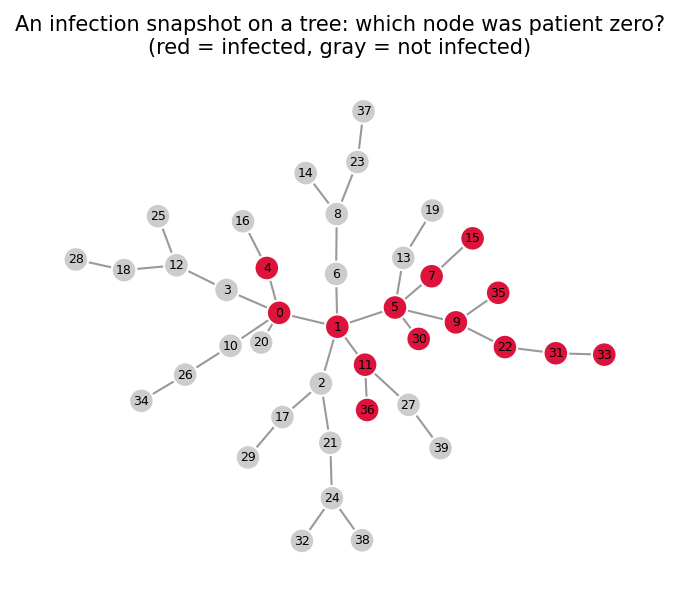

In [ ]:
T = random_tree(40, seed=3)
true_source = 7
infected = simulate_si_on_tree(T, true_source, n_infected=14, seed=11)

pos = nx.kamada_kawai_layout(T)
colors = ['crimson' if v in set(infected) else '0.8' for v in T.nodes()]

fig, ax = plt.subplots(1, 1, figsize=(5.5, 4.5), dpi=150)
nx.draw_networkx_edges(T, pos, edge_color='0.6', ax=ax)
nx.draw_networkx_nodes(T, pos, node_color=colors, node_size=140,
                       edgecolors='w', ax=ax)
nx.draw_networkx_labels(T, pos, font_size=6, ax=ax)
ax.set_title('An infection snapshot on a tree: which node was patient zero?\n'
             '(red = infected, gray = not infected)', fontsize=10)
ax.set_axis_off()
plt.show()

*(Answer revealed in Section 5: after we build rumor centrality, we will compare it with your guess.)*
__________

### Your turn
Using the snapshot in Section 1, fill in the function below so it returns the rumor centrality of every node in the infected subtree, then compare the argmax with your guess.

In [ ]:
def rumor_centrality(T_infected):
    """
    Compute the rumor centrality of every node of an infected tree.

    Parameters
    ----------
    T_infected : networkx.Graph
        The infected subtree (must be a tree).

    Returns
    -------
    R : dict
        Maps each node v to log R(v) = log(N!) - sum_u log(T_u^v), where
        T_u^v is the size of the subtree rooted at u when the tree is rooted at v.

    Citations
    ---------
    Shah & Zaman (2011). Rumors in a network: Who's the culprit?
    IEEE Transactions on Information Theory, 57(8), 5163-5181.
    """
    pass

# Part B: Inference of the Tree
## 6. Inferring the Tree Itself
*Planned content:* why tree space is huge; UPGMA and neighbor joining coded from scratch on simulated sequences with a known true tree; scoring candidate trees with the Section 4 likelihood; recovery accuracy vs. sequence length; **advanced:** NetInf for diffusion trees from cascades (small demo) and Chow-Liu trees; **Where this breaks**; **Your turn #3** (neighbor joining by hand on a 4-taxon distance matrix, then check with code).
__________

# Part C: Beyond Trees
## 7. Addressing the Limitations
*Planned content:* the roadmap table below, then each remedy as a small demo.

| Limitation (where stated) | Remedy (Section 7) |
|---|---|
| BP double-counts on cycles (Section 4) | 7.1 Loopy BP, 7.3 Junction trees |
| Rumor centrality needs a tree (Section 5) | 7.2 Spanning-tree approximation |
| Felsenstein needs a tree, but evolution can have reticulation (Sections 4, 6) | 7.4 DAGs and phylogenetic networks |
| Tree reconstruction forces a tree onto non-tree data (Section 6) | 7.4 Phylogenetic networks |
| Directed structure | 7.4 Polytrees, moralization |

Advanced sections: 7.3 and 7.4. **Your turn #4:** predict whether loopy BP will be accurate on a tree, a lattice and a sparse random graph, then test it.
__________

## 8. Wrap-up
*Planned content:* one takeaway per goal; "Next time..." pointer; connections to the sparsification, link prediction and graph distance chapters.
__________

## Limitations
Each method's limitations are stated in its own section ("Where this breaks", Sections 4 to 6). Section 7 is about addressing them, and ends with what remains unsolved: loopy BP has no general guarantees, junction trees blow up with treewidth, tree reconstruction can return a confident tree for data that is not tree-like, and model misspecification (known potentials, SI-only spreading, a single source) is not fixed by any of the remedies.
__________

## References and further resources:

1. Pearl, J. (1982). Reverend Bayes on inference engines: A distributed hierarchical approach. *Proceedings of the AAAI National Conference on AI*, 133-136.
2. Pearl, J. (1988). *Probabilistic Reasoning in Intelligent Systems: Networks of Plausible Inference*. Morgan Kaufmann.
3. Kschischang, F. R., Frey, B. J., & Loeliger, H.-A. (2001). Factor graphs and the sum-product algorithm. *IEEE Transactions on Information Theory*, 47(2), 498-519

*Planned list*

.
4. Felsenstein, J. (1981). Evolutionary trees from DNA sequences: a maximum likelihood approach. *Journal of Molecular Evolution*, 17, 368-376.
5. Jukes, T. H., & Cantor, C. R. (1969). Evolution of protein molecules. In *Mammalian Protein Metabolism* (Vol. 3, pp. 21-132). Academic Press.
6. Yedidia, J. S., Freeman, W. T., & Weiss, Y. (2005). Constructing free-energy approximations and generalized belief propagation algorithms. *IEEE Transactions on Information Theory*, 51(7), 2282-2312.
7. Newman, M. E. J. (2023). Message passing methods on complex networks. *Proceedings of the Royal Society A*, 479, 20220774.
8. Karrer, B., & Newman, M. E. J. (2010). Message passing approach for general epidemic models. *Physical Review E*, 82, 016101.
9. Shah, D., & Zaman, T. (2011). Rumors in a network: Who's the culprit? *IEEE Transactions on Information Theory*, 57(8), 5163-5181.
10. Lauritzen, S. L., & Spiegelhalter, D. J. (1988). Local computations with probabilities on graphical structures and their application to expert systems. *Journal of the Royal Statistical Society B*, 50(2), 157-224.
11. Murphy, K. P., Weiss, Y., & Jordan, M. I. (1999). Loopy belief propagation for approximate inference: An empirical study. *Proceedings of UAI*, 467-475.
12. Huson, D. H., Rupp, R., & Scornavacca, C. (2010). *Phylogenetic Networks: Concepts, Algorithms and Applications*. Cambridge University Press.
13. Koutra, D., Vogelstein, J. T., & Faloutsos, C. (2013). DeltaCon: A principled massive-graph similarity function. *Proceedings of the 2013 SIAM International Conference on Data Mining*, 162-170.
14. Newman, M. E. J. (2018). *Networks* (2nd ed.). Oxford University Press.
15. Felsenstein, J. (2004). *Inferring Phylogenies*. Sinauer Associates.
16. Saitou, N., & Nei, M. (1987). The neighbor-joining method: a new method for reconstructing phylogenetic trees. *Molecular Biology and Evolution*, 4(4), 406-425.
17. Sokal, R. R., & Michener, C. D. (1958). A statistical method for evaluating systematic relationships. *University of Kansas Science Bulletin*, 38, 1409-1438.
18. Gomez-Rodriguez, M., Leskovec, J., & Krause, A. (2010). Inferring networks of diffusion and influence. *Proceedings of KDD*, 1019-1028.
19. Chow, C. K., & Liu, C. N. (1968). Approximating discrete probability distributions with dependence trees. *IEEE Transactions on Information Theory*, 14(3), 462-467.

